# State-space models: what can we infer between measurements?

A state-space model separates a hidden process from the measurements it generates. Filtering conditions on observations available up to each time. Smoothing revisits earlier states using the full observation series. This distinction matters most where measurements are noisy or missing.

We start with exact linear Gaussian inference on irregular times, inspect how the process-noise assumption changes the result, then reuse the same contracts for nonlinear and count observations. Generated latent states supply a reference for inspection. Model parameters are fixed here; state uncertainty does not include parameter uncertainty.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import distributions as dist, state_space as ss

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## Position is measured; velocity is latent

For a local linear trend with state $x=(p,v)$, the elapsed-time transition and process covariance are

$$F(\Delta t)=\begin{pmatrix}1&\Delta t\\0&1\end{pmatrix},\qquad
Q(\Delta t)=q\begin{pmatrix}\Delta t^3/3&\Delta t^2/2\\\Delta t^2/2&\Delta t\end{pmatrix}.$$

Here $q$ is the variance rate of the driving acceleration noise, and the observation variance is $R=0.5$. The initial law describes the state at the **first** timestamp. Simulate irregular timestamps, remove scattered observations and a longer block, and retain the missing rows so their elapsed time remains visible.

In [2]:
times = np.r_[0., np.cumsum(rng.uniform(.2, 1.5, 99))]
initial = ss.GaussianState([0., .4], [[.1, 0.], [0., .1]])
model = ss.local_linear_trend(.03, .5, initial=initial)
generated = ss.simulate(model, times, rng=np.random.default_rng(12))
y = generated.observations.values.copy()
y[::7] = np.nan
y[40:49] = np.nan
data = ss.TimeSeries(y, times, names=("position",))
result = ss.KalmanFilter().smooth(model, data)
pd.DataFrame({"time": times, "elapsed": np.r_[0., np.diff(times)], "observed position": y[:, 0],
              "true position": generated.states[:, 0], "true velocity": generated.states[:, 1]}).head(10)

,time,elapsed,observed position,true position,true velocity
0,0.000000,0.000000,NaN,-0.002159,0.730820
1,1.206143,1.206143,0.193654,1.046112,1.057010
2,1.976685,0.770542,1.722112,1.798304,0.849450
3,3.292862,1.316177,3.213761,2.863121,0.881685
4,4.399441,1.106578,3.296033,3.937339,0.858670
5,4.721871,0.322431,4.883836,4.212545,0.948457
6,6.190180,1.468309,6.177381,5.712182,1.071545
7,7.379662,1.189482,NaN,6.942375,0.968445
8,8.601545,1.221884,7.878736,8.079112,0.837048
9,8.968093,0.366548,7.280029,8.408632,0.915945


## Missing observations propagate uncertainty

A missing measurement skips the observation update. The transition still advances the state over the actual time gap and adds process uncertainty. The filter therefore becomes less certain across the missing block; the smoother can use measurements after the block to refine earlier estimates.

Bands below are 95% **marginal** Gaussian intervals at each time. They are not a simultaneous band for the whole trajectory. Smoothing is useful for retrospective reconstruction; its use of later observations prevents interpreting it as an online forecast.

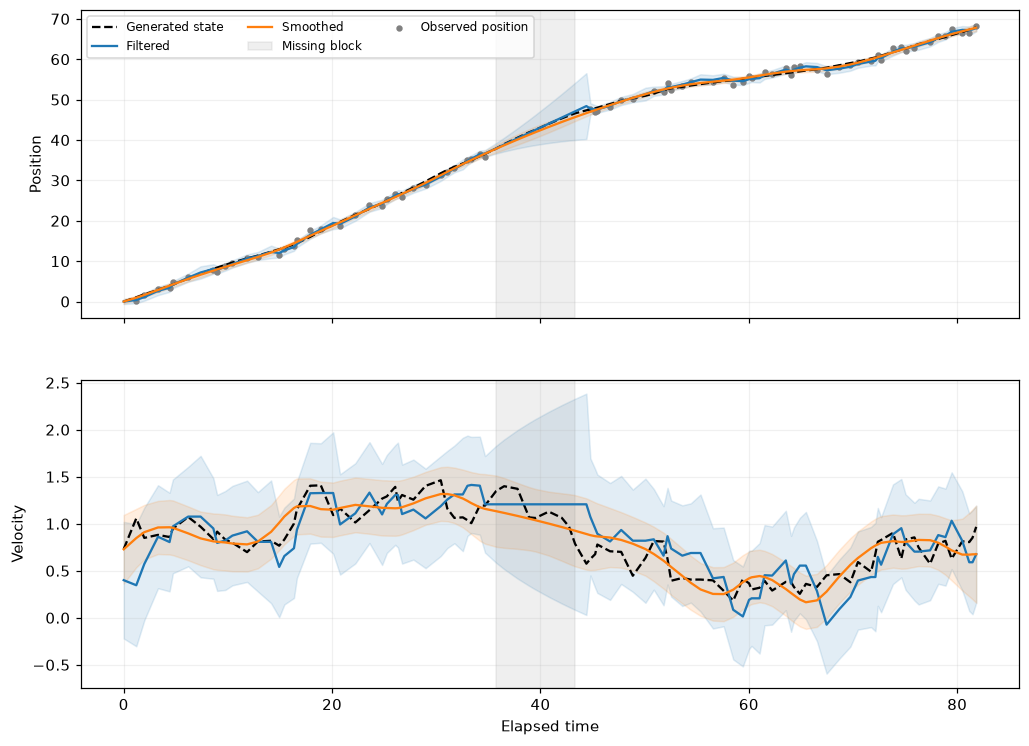

,Filtered RMSE,Smoothed RMSE
Position,0.481723,0.317148
Velocity,0.229168,0.144900


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for j, (ax, name) in enumerate(zip(axes, ("Position", "Velocity"))):
    ax.plot(times, generated.states[:, j], "k--", label="Generated state")
    for label, states, color in (("Filtered", result.filtered, "C0"), ("Smoothed", result.smoothed, "C1")):
        sd = np.sqrt(states.covariance[:, j, j])
        ax.plot(times, states.mean[:, j], color=color, label=label)
        ax.fill_between(times, states.mean[:, j]-1.96*sd, states.mean[:, j]+1.96*sd, color=color, alpha=.13)
    ax.axvspan(times[40], times[48], color="gray", alpha=.12, label="Missing block")
    ax.set(ylabel=name)
axes[0].scatter(times, y[:, 0], s=10, color="gray", label="Observed position")
axes[0].legend(ncol=3, fontsize=8)
axes[1].set(xlabel="Elapsed time")
plt.show()
pd.DataFrame({name: np.sqrt(np.mean((states.mean-generated.states)**2, axis=0))
              for name, states in (("Filtered RMSE", result.filtered), ("Smoothed RMSE", result.smoothed))},
             index=["Position", "Velocity"])

## A noise assumption changes what the filter calls motion

A small process variance rate favors a nearly constant velocity. A large value permits faster changes but gives the noisy measurements more influence. Inspect this tradeoff on exactly the same observations and initial law.

Standardized innovations divide each observed residual by its predictive standard deviation. Under the correct model they have unit marginal variance and no serial correlation; a single plot and likelihood value do not establish calibration. Missing entries remain gaps. The likelihood uses only observed measurements.

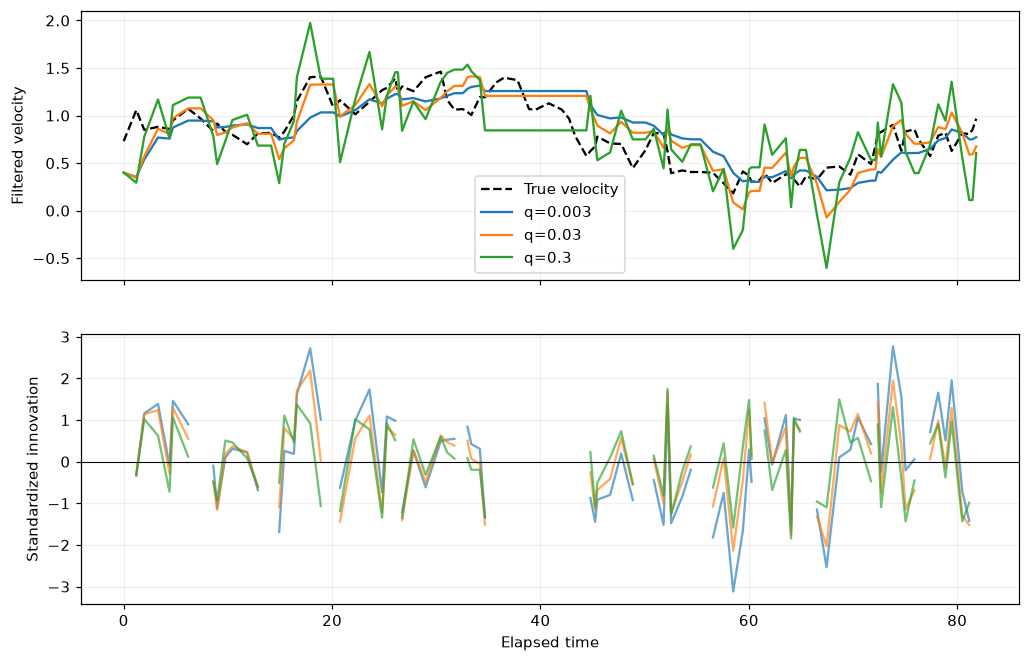

,Log likelihood,Velocity RMSE
Process variance rate,,
0.003,-112.152046,0.235354
0.030,-109.321018,0.229168
0.300,-120.636582,0.354940


In [4]:
sensitivity = {q: ss.KalmanFilter().filter(ss.local_linear_trend(q, .5, initial=initial), data)
               for q in (.003, .03, .3)}
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(times, generated.states[:, 1], "k--", label="True velocity")
for q, estimate in sensitivity.items():
    axes[0].plot(times, estimate.filtered.mean[:, 1], label=f"q={q:g}")
    residual = estimate.innovations[:, 0]/np.sqrt(estimate.observation_covariance[:, 0, 0])
    axes[1].plot(times, residual, alpha=.65, label=f"q={q:g}")
axes[0].set(ylabel="Filtered velocity")
axes[0].legend()
axes[1].axhline(0, color="k", lw=.7)
axes[1].set(xlabel="Elapsed time", ylabel="Standardized innovation")
plt.show()
pd.DataFrame({q: {"Log likelihood": estimate.log_likelihood,
                  "Velocity RMSE": np.sqrt(np.mean((estimate.filtered.mean[:, 1]-generated.states[:, 1])**2))}
              for q, estimate in sensitivity.items()}).T.rename_axis("Process variance rate")

## A latent-state law preserves dependence between coordinates

At a chosen time inside the missing block, `distribution()` returns the smoothed joint law of position and velocity. The cloud's shape reflects their covariance; inspect the off-diagonal entry in the table rather than assuming these coordinates are independent. Drawing this law independently at every time would discard temporal dependence and would not produce smoothing paths.

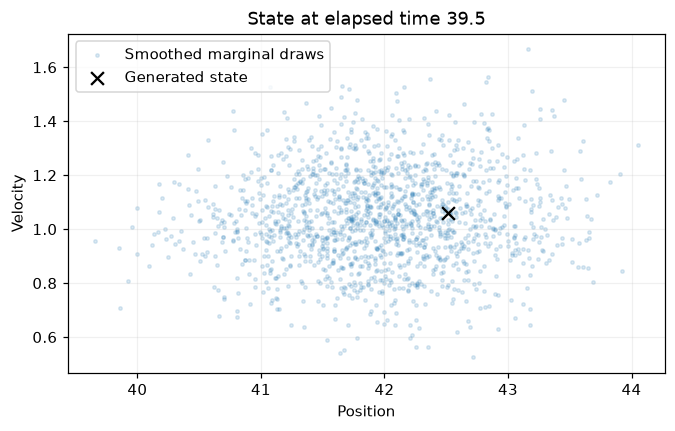

,position,velocity
position,0.511602,0.004066
velocity,0.004066,0.028808


In [5]:
row = 44
state_law = result.smoothed.distribution(row)
draws = state_law.sample(1500, rng=rng)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(draws[:, 0], draws[:, 1], s=5, alpha=.15, label="Smoothed marginal draws")
ax.scatter(*generated.states[row], marker="x", color="k", s=70, label="Generated state")
ax.set(xlabel="Position", ylabel="Velocity", title=f"State at elapsed time {times[row]:.1f}")
ax.legend()
plt.show()
pd.DataFrame(state_law.covariance(), index=result.state_names, columns=result.state_names)

## Nonlinear Gaussian models: local linearization or sigma points

Define a nonlinear transition $x'=x-0.2\sin(x)\Delta t+\epsilon$ and observation $y=x+0.05x^3+\eta$. Both noises are Gaussian and additive. The extended filter uses the supplied Jacobians; the unscented filter propagates sigma points through the same functions. These are Gaussian approximations, so neither is universally superior.

The transition is the specified discrete model for each elapsed interval, not an exact continuous-time nonlinear SDE solution. The elapsed interval explicitly enters both drift and process variance. Convexity's nonlinear smoothers then run the corresponding backward recursion. In this realization, states remain near zero, where the cubic observation term is small, and the two smoothed means nearly overlap. Moving the initial mean farther from zero provides a stronger curvature experiment.

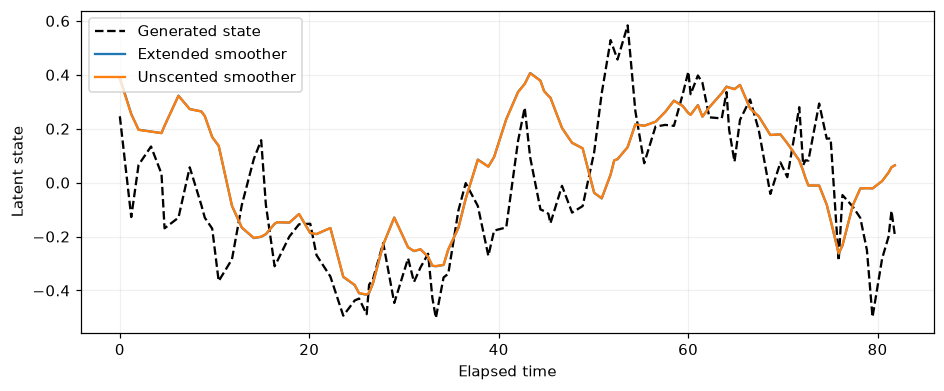

,Filtered RMSE,Smoothed RMSE
Extended,0.248891,0.232586
Unscented,0.248946,0.232373


In [6]:
transition = ss.GaussianTransition(1,
    lambda x, step: x-.2*np.sin(x)*step.dt,
    lambda step: [[.03*step.dt]],
    lambda x, step: [[1-.2*np.cos(x[0])*step.dt]])
nonlinear = ss.StateSpaceModel(ss.GaussianState([.5], [[.1]]), transition,
    ss.GaussianObservation(1, 1, lambda x, step: x+.05*x**3, [[.2]],
        lambda x, step: [[1+.15*x[0]**2]]), time_mode="elapsed")
nonlinear_data = ss.simulate(nonlinear, times, rng=np.random.default_rng(9))
approximations = {"Extended": ss.ExtendedKalmanFilter().smooth(nonlinear, nonlinear_data.observations),
                  "Unscented": ss.UnscentedKalmanFilter().smooth(nonlinear, nonlinear_data.observations)}
fig, ax = plt.subplots()
ax.plot(times, nonlinear_data.states[:, 0], "k--", label="Generated state")
for name, estimate in approximations.items():
    ax.plot(times, estimate.smoothed.mean[:, 0], label=f"{name} smoother")
ax.set(xlabel="Elapsed time", ylabel="Latent state")
ax.legend()
plt.show()
pd.DataFrame({name: {"Filtered RMSE": np.sqrt(np.mean((estimate.filtered.mean-nonlinear_data.states)**2)),
                    "Smoothed RMSE": np.sqrt(np.mean((estimate.smoothed.mean-nonlinear_data.states)**2))}
              for name, estimate in approximations.items()}).T

## Count observations require a different observation law

Replace the observation with $Y_t\mid x_t\sim\mathrm{Poisson}(3e^{x_t})$, keeping the nonlinear state transition. This measures a count at each timestamp; it is not an integrated count over the preceding interval. An exposure model would need an explicit interval factor.

The bootstrap particle filter represents the posterior by weighted particles. Effective sample size, $1/\sum_i w_i^2$, indicates weight concentration. Resampling at a row is triggered using the previous row's weights, so markers need not coincide with the lowest current ESS.

Backward simulation samples coherent latent trajectories using transition densities. Unlike independent draws from time marginals, these paths retain temporal dependence. They and the resulting smoother are Monte Carlo approximations.

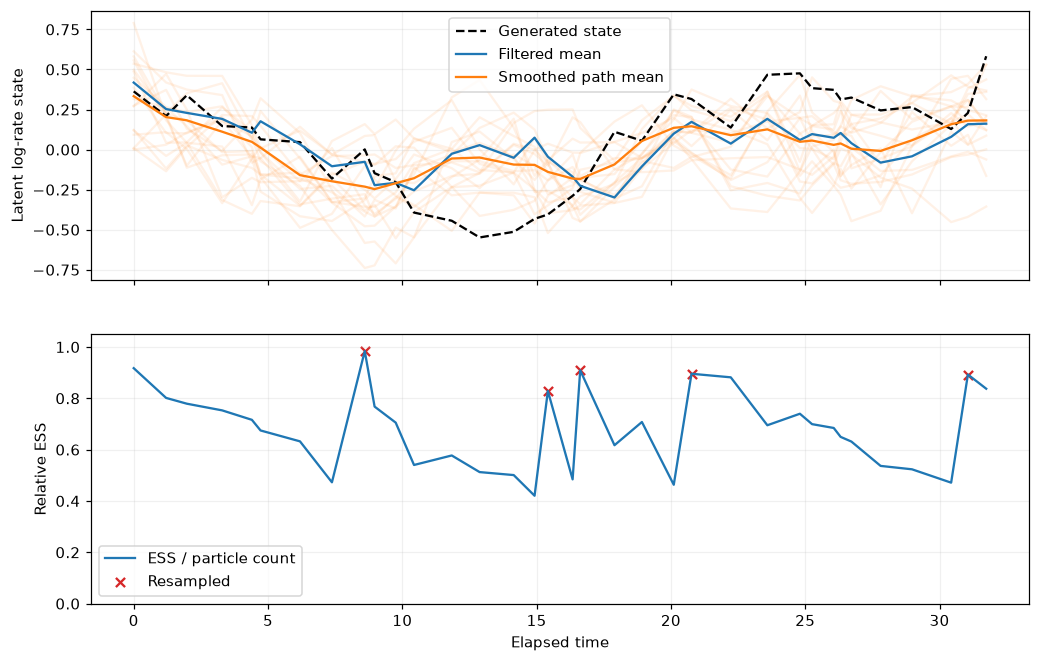

In [7]:
count_model = ss.StateSpaceModel(nonlinear.initial, transition,
    ss.DistributionObservation(1, 1, lambda x, step: dist.independent([dist.poisson(3*np.exp(x[0]))])),
    time_mode="elapsed")
counts = ss.simulate(count_model, times[:35], rng=np.random.default_rng(18))
particle_filter = ss.ParticleFilter(700)
particles = particle_filter.filter(count_model, counts.observations, rng=np.random.default_rng(19))
particle_smoother = particle_filter.smooth_result(particles, paths=120, method="backward", rng=np.random.default_rng(20))
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(counts.observations.timestamps, particle_smoother.paths[:18, :, 0].T, color="C1", alpha=.1)
axes[0].plot(times[:35], counts.states[:, 0], "k--", label="Generated state")
axes[0].plot(times[:35], particles.filtered.mean[:, 0], label="Filtered mean")
axes[0].plot(times[:35], particle_smoother.smoothed.mean[:, 0], label="Smoothed path mean")
axes[0].set(ylabel="Latent log-rate state")
axes[0].legend()
ess = particles.effective_sample_size/700
axes[1].plot(times[:35], ess, label="ESS / particle count")
axes[1].scatter(times[:35][particles.resampled], ess[particles.resampled], marker="x", color="C3", label="Resampled")
axes[1].set(xlabel="Elapsed time", ylabel="Relative ESS", ylim=(0, 1.05))
axes[1].legend()
plt.show()

The posterior expected count is $3E[e^x\mid y_{0:t}]$, which generally differs from $3e^{E[x\mid y_{0:t}]}$. Evaluate the nonlinear quantity against the weighted state law. These are filtered fitted rates after seeing the current count, not one-step predictions.

In [8]:
pd.DataFrame({"Observed count": counts.observations.values[:10, 0],
              "Generating rate": 3*np.exp(counts.states[:10, 0]),
              "Posterior expected rate": [particles.filtered.distribution(i).expect(lambda x: 3*np.exp(x[0])) for i in range(10)],
              "Rate at posterior mean": 3*np.exp(particles.filtered.mean[:10, 0])},
             index=pd.Index(times[:10], name="Elapsed time"))

,Observed count,Generating rate,Posterior expected rate,Rate at posterior mean
Elapsed time,,,,
0.000000,4.0,4.314124,4.712899003050351,4.557911
1.206143,3.0,3.698161,3.973399991962039,3.863364
1.976685,4.0,4.211258,3.875192837352843,3.772241
3.292862,4.0,3.475318,3.730993047074779,3.633382
4.399441,3.0,3.442783,3.421611401797862,3.332618
4.721871,5.0,3.198417,3.6669144591347664,3.580282
6.190180,2.0,3.142911,3.1932929281041984,3.100530
7.379662,1.0,2.503080,2.7806403361257086,2.703778
8.601545,3.0,3.003409,2.8651300544798493,2.779647


Numeric elapsed times above use the units implied by the process parameters. Datetime elapsed models require an explicit `time_unit`; observation-index models do not infer dynamics from timestamp gaps. The [state-space guide](../state_space.md) describes partial missing measurements, backend support, and the distinction between ancestral and backward particle smoothing. Parameter estimation is a separate operation, illustrated in [the generated-data estimation example](../examples/state_space_estimation.py).